### Загружаем датасет по варианту и выводим информацию о столбцах:

In [52]:
import pandas as pd

df = pd.read_csv("./data/Diamonds-Prices.csv")

df

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...,...
53938,53939,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,53940,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64
53940,53941,0.71,Premium,E,SI1,60.5,55.0,2756,5.79,5.74,3.49
53941,53942,0.71,Premium,F,SI1,59.8,62.0,2756,5.74,5.73,3.43


Заменим пустые значения в столбце bmi на медиану:

In [53]:
df["price"] = df["price"].fillna(df["price"].median())

### Создадим лингвистические переменные

Входные: age (возраст пациента) и networth (чистая стоимость)

Выходные: influence (влияние)

In [54]:
import numpy as np
from skfuzzy import control as ctrl

carat = ctrl.Antecedent(
    np.arange(df["carat"].min(), df["carat"].max() + 0.01, 0.01), "carat"
)
depth = ctrl.Antecedent(
    np.arange(df["depth"].min(), df["depth"].max() + 0.1, 0.1), "depth"
)
price = ctrl.Consequent(np.arange(df["price"].min(), df["price"].max() + 1, 1), "price")

Далее произведем их настройку:

g:\МИИ\MAI_PIbd-33_Tikhonenkov_A_E\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


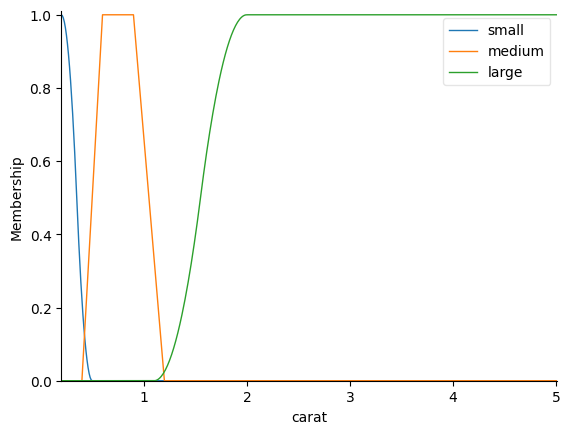

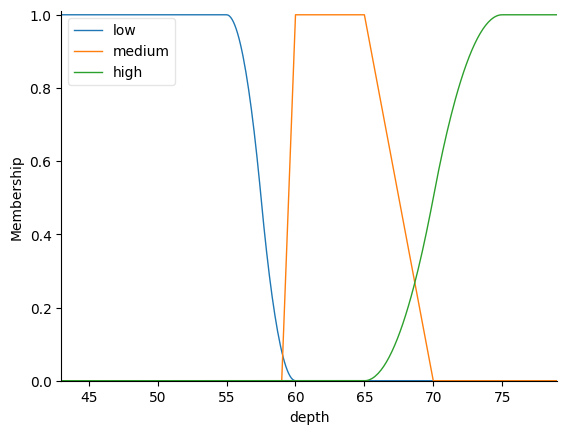

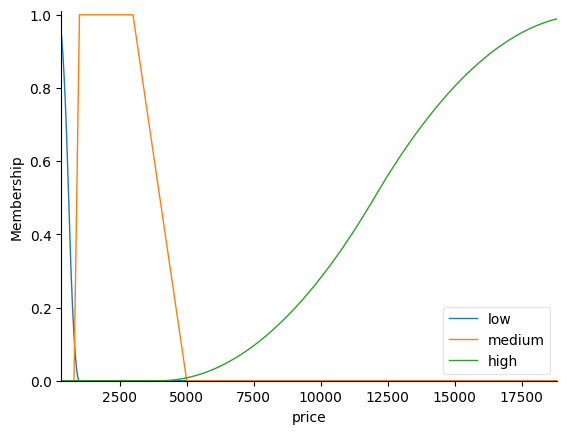

In [55]:
import skfuzzy as fuzz

carat["small"] = fuzz.zmf(carat.universe, 0.2, 0.5)
carat["medium"] = fuzz.trapmf(carat.universe, [0.4, 0.6, 0.9, 1.2])
carat["large"] = fuzz.smf(carat.universe, 1.1, 2.0)
carat.view()

depth["low"] = fuzz.zmf(depth.universe, 55, 60)
depth["medium"] = fuzz.trapmf(depth.universe, [59, 60, 65, 70])
depth["high"] = fuzz.smf(depth.universe, 65, 75)
depth.view()

price["low"] = fuzz.zmf(price.universe, 200, 1000)
price["medium"] = fuzz.trapmf(price.universe, [800, 1000, 3000, 5000])
price["high"] = fuzz.smf(price.universe, 4000, 20000)
price.view()

### Сформируем базу нечетких правил:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

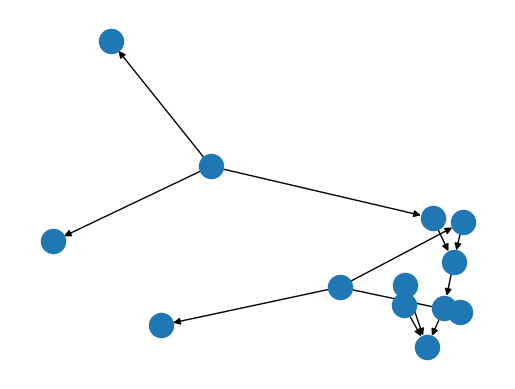

In [56]:
rule1 = ctrl.Rule(carat["small"] & depth["low"], price["low"])
rule2 = ctrl.Rule(carat["small"] & depth["medium"], price["medium"])
rule3 = ctrl.Rule(carat["small"] & depth["high"], price["medium"])

rule4 = ctrl.Rule(carat["medium"] & depth["low"], price["medium"])
rule5 = ctrl.Rule(carat["medium"] & depth["medium"], price["medium"])
rule6 = ctrl.Rule(carat["medium"] & depth["high"], price["high"])

rule7 = ctrl.Rule(carat["large"] & depth["low"], price["high"])
rule8 = ctrl.Rule(carat["large"] & depth["medium"], price["high"])
rule9 = ctrl.Rule(carat["large"] & depth["high"], price["high"])

rule1.view()

Создадим нечеткую систему и добавим созданные нечеткие правила в ее базу знаний:

g:\МИИ\MAI_PIbd-33_Tikhonenkov_A_E\.venv\Lib\site-packages\skfuzzy\control\controlsystem.py:135: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


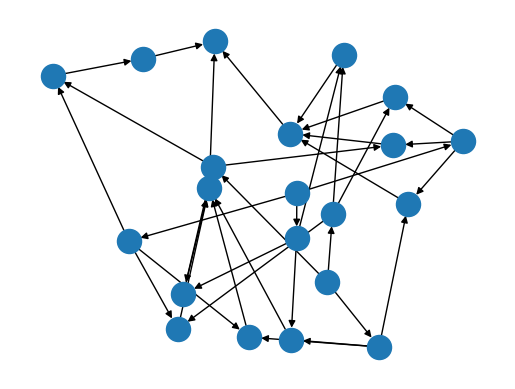

In [57]:
price_ctrl = ctrl.ControlSystem(
    [rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9]
)

price_simulation = ctrl.ControlSystemSimulation(price_ctrl)

price_ctrl.view()

### Теперь можно выполнить оценку качества полученной нечеткой системы.

Для начала проверим работу системы на единичном примере:

In [58]:
price_simulation.input["carat"] = 0.3  # Пример значения для carat
price_simulation.input["depth"] = 62  # Пример значения для depth

price_simulation.compute()

price_simulation.print_state()
price_simulation.output["price"]

 Antecedents 
Antecedent: carat                   = 0.3
  - small                           : 0.7777777777777778
  - medium                          : 0.0
  - large                           : 0.0
Antecedent: depth                   = 62
  - low                             : 0.0
  - medium                          : 1.0
  - high                            : 0.0

 Rules 
RULE #0:
  IF carat[small] AND depth[low] THEN price[low]
	AND aggregation function : fmin
	OR aggregation function  : fmax

  Aggregation (IF-clause):
  - carat[small]                                           : 0.7777777777777778
  - depth[low]                                             : 0.0
                               carat[small] AND depth[low] = 0.0
  Activation (THEN-clause):
                                                price[low] : 0.0

RULE #1:
  IF carat[small] AND depth[medium] THEN price[medium]
	AND aggregation function : fmin
	OR aggregation function  : fmax

  Aggregation (IF-clause):
  - carat[sma

np.float64(2579.844961240246)

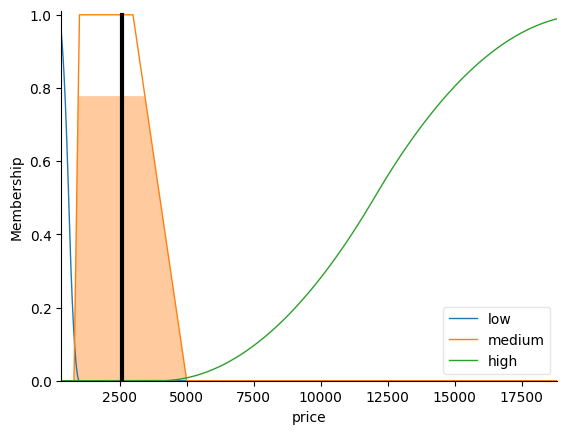

In [59]:
price.view(sim=price_simulation)

Также сравним результаты работы системы с реальными данными:

In [60]:
def fuzzy_pred(row):
    price_simulation.input["carat"] = row["carat"]
    price_simulation.input["depth"] = row["depth"]
    price_simulation.compute()
    return price_simulation.output["price"]

In [61]:
result = df.copy()

result["price_pred"] = result.apply(fuzzy_pred, axis=1)

result.loc[240:260, ["carat", "depth", "price", "price_pred"]]

,carat,depth,price,price_pred
240,0.71,62.5,2788,2503.225806
241,1.01,64.5,2788,2633.891532
242,1.01,62.7,2788,2633.891532
243,0.77,64.2,2789,2503.225806
244,0.76,63.7,2789,2503.225806
245,0.76,60.4,2789,2503.225806
246,0.76,61.8,2789,2503.225806
247,1.05,63.2,2789,2686.301370
248,0.81,61.6,2789,2503.225806
249,0.70,61.6,2789,2503.225806


И оценим эти результаты с помощью метрик для задачи регрессии:

In [64]:
import math
from sklearn import metrics

rmetrics = {}
rmetrics["RMSE"] = math.sqrt(
    metrics.mean_squared_error(result["price"], result["price_pred"])
)
rmetrics["RMAE"] = math.sqrt(
    metrics.mean_absolute_error(result["price"], result["price_pred"])
)
rmetrics["R2"] = metrics.r2_score(result["price"], result["price_pred"])

rmetrics

{'RMSE': 2710.116975448269,
 'RMAE': 45.737332756192025,
 'R2': 0.5384886786875415}

Как можно заметить, нечеткая система с такими переменными и настройками со своей задачей справляется плохо